# SubPOP test set: released vs fine-tuned Kev

1. **SubPOP test set**: the error on every test question row, then answer distributions of single test questions.
2. **US records: training, calibration and test**: answer distributions of US records of each kind, observed vs every model.
3. **Does the fine-tuned model use gender?** One training question and one calibration question.

The test set is SubPOP's evaluation split (`subpop_eval`): 133 US General Social Survey questions, each answered by up to 22 US subpopulations (e.g. all Democrats, all Black respondents), 2,926 question rows. None of it was used in training; questions that ISSP also asks (in other words) are kept, as are all others (`data/subpop/README.md`, decision 4). Each fine-tuned model was trained on the ISSP data its run's recipe names (all countries, or only the US: `configs/data/`); its best step was picked on that run's calibration set (ISSP slots held out of training).

For every question row, the model's predicted answer shares are compared with the group's observed shares:

- **KL divergence** (bits) and **JS divergence**: for every question; 0 = identical.
- **Wasserstein distance** as % of the scale range: for Likert (`score`) questions only, since it needs ordered answers; 0 = identical.

**No temperature anywhere, not even post hoc.** Every model is scored on its raw distribution (softmax of its scores, T = 1): no temperature is fitted or applied, on the calibration set or any other, because rescaling would only hide how well the model fits (`data/issp2020/DECISIONS.md`, 11).

There is no human benchmark: SubPOP gives only answer shares, not how many people answered, so the sampling error cannot be computed.

In [167]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

import models   # the model layer: models.load reads any saved model (Kev or LLM)
import train    # the test set, prediction and error measures used in training
from issp_sampler import IsspSource   # the ISSP respondent data
from training_data import TrainingData, recipe_from_settings   # a run's training data, rebuilt from its recipe

MODELS = {
    # "Kev 0.8B released": "jaredpalmer/kev-0.8b",
    # "Kev 0.8B fine-tuned full": "runs/issp-all-0.8b-full-v1/best",
    # "Qwen3.5 0.8B letters": "runs/issp-all-qwen0.8b-letters-v1/best",
    # "Kev 0.8B full, US only": "runs/issp-us-0.8b-full-min100-attr2-v1/best",
    # "Kev 0.8B full, US only 2-4": "runs/issp-us-0.8b-full-min100-attr2-4-noaug-v1/best",
    # "Kev 0.8B full, US only 2-4 4B": "runs/unfreeze-4b-l3-v1/best",
    "Kev 0.8B full, US only 2-4 9B Best": "runs/lora-9b-r64-v2/best",
    "Kev 0.8B full, US only 2 9B Best": "runs/lora-9b-r64-attr2-v1/best",
    "Kev 0.8B full, US only 2 9B Last": "runs/lora-9b-r64-attr2-v1/last",
}
EX_MODEL = list(MODELS.keys())[-1]
TEST = train.TEST_DATASET
test_records = train.read_records(TEST)
sum(len(r["questions"]) for r in test_records)   # question rows in the test set

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


2926

## Model predictions

A model's predictions are computed once and saved in `runs/predictions/`; later runs load them. They are recomputed when the checkpoint is retrained or the test rows change.

In [168]:
import transformers.models.qwen3_5.modeling_qwen3_5 as _qwen3_5

CACHE = Path("runs/predictions")   # saved predictions: runs/predictions/<model>/<set name>.pt
EVAL_BATCH = 32                    # records per forward pass
device = "cpu"                     # "cpu" or "cuda"
# device = "cuda"                     # "cpu" or "cuda"

_QWEN_KERNELS = ("causal_conv1d_fn", "causal_conv1d_update", "torch_chunk_gated_delta_rule", "torch_recurrent_gated_delta_rule")
for _k in _QWEN_KERNELS:
    setattr(_qwen3_5, f"_orig_{_k}", getattr(_qwen3_5, f"_orig_{_k}", getattr(_qwen3_5, _k)))

def fingerprint(run, records):
    """What the saved predictions depend on: the checkpoint (for a local run, when its weights were last written) and
    the exact rows predicted. If either changes, the saved predictions are not used."""
    marker = next((Path(run) / name for name in ("head.pt", "letters.json") if (Path(run) / name).exists()), None)
    weights = marker.stat().st_mtime if marker else run   # released models: the Hugging Face name
    return {"weights": weights, "rows": [(r["group"], v) for r in records for v in r["questions"]]}

def cached_predictions(run, named_records, device=device):
    """{set name: one {v, type, target, probs} per question row, in record order} for one model. Saved predictions are
    loaded; the model is loaded onto `device` ('cpu' or 'cuda') only if some set has to be computed, and new results are saved."""
    device_type = torch.device(device).type
    autocast = torch.autocast(device_type, dtype=torch.bfloat16)
    for _k in _QWEN_KERNELS:
        _fn = getattr(_qwen3_5, f"_orig_{_k}")
        setattr(_qwen3_5, _k, getattr(_fn, "__wrapped__", _fn) if device_type == "cpu" else _fn)
    result, model = {}, None
    for set_name, records in named_records.items():
        path = CACHE / run.replace("/", "__") / f"{set_name}.pt"
        saved = torch.load(path, map_location="cpu") if path.exists() else None
        if saved is not None and saved["fingerprint"] == fingerprint(run, records):
            result[set_name] = saved["predictions"]          # load instead of recomputing
            continue
        if model is None:
            model = models.load(run, device)   # raw distribution: no temperature
        result[set_name] = train.with_probs(train.predict(model, records, EVAL_BATCH, autocast))
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({"fingerprint": fingerprint(run, records), "predictions": result[set_name]}, path)
    print(f"{run}: {'computed' if model is not None else 'loaded from ' + str(CACHE)}")
    del model
    if device_type == "cuda":
        torch.cuda.empty_cache()
    return result


## Plotting

Every plot below shows answer distributions the same way: one smoothed curve per entity, one color per entity throughout.

In [169]:
import textwrap
import matplotlib.pyplot as plt
import seaborn as sns

HUMANS = "Humans (observed)"
COLORS = dict(zip([HUMANS, *MODELS], sns.color_palette()))   # one color per entity, the same in every plot

def plot_shares(ax, curves, criteria, labels={}, wrap=14):
    """Answer distributions of one Likert question on one panel: every entity's shares as a smoothed curve over the
    ordered answers, filled and see-through. curves: {entity: shares}; labels: {entity: legend text} where it should
    say more than the entity's name."""
    levels = np.arange(len(criteria))
    for entity, p in curves.items():
        sns.kdeplot(x=levels, weights=np.asarray(p), bw_adjust=0.5, cut=0, fill=True, alpha=0.3, linewidth=2,
                    label=labels.get(entity, entity), color=COLORS[entity], ax=ax)
    ax.set_xticks(levels, [textwrap.fill(level, wrap) for level in criteria])
    if len(criteria) > 6:   # long scales: smaller, tilted answer labels so they do not overlap
        ax.tick_params(axis="x", labelsize=7, labelrotation=30)
    ax.set_ylabel("Density")   # smoothed: the area under each curve is the probability

## 1. US records: training, calibration and test

`EX_MODEL`'s run on one question per set, for the groups that answer it most differently; every panel is one group, its observed answer shares vs every model in `MODELS`.

- **Training**: a US question the run trained on (one of its slots; in training each draw had a fresh persona, so these exact groups may never have been drawn).
- **Calibration**: a US question held out of the run's training (never trained on; used to pick its best step).
- **Test**: a SubPOP question (the US General Social Survey; mostly questions ISSP does not ask).

**Personas.** For every attribute, its two values whose groups answer the question most differently (Wasserstein distance, as a share of the scale); the `CONTRAST_ROWS` attributes with the largest such gaps are the rows. ISSP groups have at least `MIN_GROUP` respondents, so their observed shares are reliable (SubPOP does not say how many); attributes that split the respondents identically (in the US, the party voted for and its left-right position) are shown once. **Question.** The Likert question of the set whose rows differ most, unless the cell names one. Both are chosen from the observed answers only, not from how any model does. The legend gives each model's KL divergence (bits) and the group's size.

In [157]:
import itertools
import json

from issp_augment import canonical
from models.base import options_and_targets

TRAIN_RUN = Path(MODELS[EX_MODEL]).parent   # the run the fine-tuned checkpoint comes from
SETTINGS = json.loads((TRAIN_RUN / "run_info.json").read_text())["settings"]
RUN_DATA = TrainingData(recipe_from_settings(SETTINGS))   # its training slots and held-out slots, rebuilt from its recipe
SOURCE = RUN_DATA.source
MIN_GROUP = 100      # respondents an ISSP group must have to be shown
CONTRAST_ROWS = 3    # attributes shown, each with its two most different values

def gap(p, q):
    """How differently two groups answer: Wasserstein distance as a share of the scale range (0 = the same)."""
    return train.wasserstein(torch.as_tensor(p, dtype=torch.float), torch.as_tensor(q, dtype=torch.float)) / (len(p) - 1)

def contrasts(groups):
    """groups = {attribute: {value: shares}} -> the CONTRAST_ROWS attributes whose two most different values differ
    most: [(gap, attribute, value_a, value_b)], largest first."""
    best = []
    for attribute, values in groups.items():
        pairs = [(gap(values[a], values[b]), a, b) for a, b in itertools.combinations(values, 2)]
        if pairs:
            best.append((*max(pairs), attribute))
    return [(g, attribute, a, b) for g, a, b, attribute in sorted(best, reverse=True)[:CONTRAST_ROWS]]

def issp_groups(slot):
    """{attribute: {value: shares}} of one ISSP slot: every value of every attribute with >= MIN_GROUP respondents who
    answered; an attribute that splits them exactly as an earlier one does is left out."""
    unit, v = SOURCE.units[slot[0]], slot[1]
    answers = unit.answers[v]
    groups, splits = {}, set()
    for j, attribute in enumerate(unit.attribute_names):
        values, masks = {}, []
        for code in np.unique(unit.attrs[:, j][unit.attrs[:, j] >= 0]):
            mask = (unit.attrs[:, j] == code) & (answers >= 0)
            if mask.sum() >= MIN_GROUP:
                values[unit.values[j][code]] = np.bincount(answers[mask], minlength=len(unit.keys[v])) / mask.sum()
                masks.append(mask.tobytes())
        split = frozenset(masks)
        if len(values) >= 2 and split not in splits:
            groups[attribute] = values
            splits.add(split)
    return groups

def issp_panels(slots, question=None):
    """The question of `slots` (`question`, e.g. ("issp2022", "v6"); None: chosen as above) and its rows: [(attribute, [record, record])], each record one
    group with that one question (the stored format calibration and training use)."""
    likert = [s for s in slots if SOURCE.units[s[0]].questions[s[1]]["type"] == "score"]
    if question:
        slot = next(s for s in likert if (SOURCE.units[s[0]].name, s[1]) == tuple(question))
    else:
        slot = max(likert, key=lambda s: sum(g for g, *_ in contrasts(issp_groups(s))))
    unit, v = SOURCE.units[slot[0]], slot[1]
    pool = SOURCE.pool(unit, [v])
    rows = []
    for _, attribute, *values in contrasts(issp_groups(slot)):
        j = unit.attribute_names.index(attribute)
        rows.append((attribute, [SOURCE.make(unit, [v], [j], [unit.values[j].index(value)],
                                             pool[unit.attrs[pool, j] == unit.values[j].index(value)]) for value in values]))
    return f"{unit.name} {v}", rows

def test_panels(question=None):
    """The SubPOP question (`question`, e.g. "fefam"; None: chosen as above) and its rows, from the test set's one-attribute groups."""
    by_question = {}
    for r in test_records:
        _, attribute, value = r["group"].split("/", 2)
        for v, q in r["questions"].items():
            if q["type"] == "score":
                by_question.setdefault(v, {}).setdefault(attribute, {})[value] = {**r, "questions": {v: q}}
    shares = lambda record: options_and_targets(canonical(record))[1][0]["target"]
    def rows_of(v):
        groups = {a: {value: shares(rec) for value, rec in values.items()} for a, values in by_question[v].items()}
        return [(a, [by_question[v][a][x], by_question[v][a][y]]) for _, a, x, y in contrasts(groups)]
    v = question or max(by_question, key=lambda v: sum(gap(shares(a), shares(b)) for _, (a, b) in rows_of(v)))
    return f"SubPOP {v}", rows_of(v)

def plot_panels(title, set_name, question, rows):
    """One row per attribute, one panel per group: observed vs every model's predicted answer shares."""
    records = [record for _, pair in rows for record in pair]
    predicted = {name: cached_predictions(run, {set_name: records})[set_name] for name, run in MODELS.items()}
    (v, q), = records[0]["questions"].items()
    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 3.6 * len(rows)), sharex=True, sharey=True, squeeze=False)
    for k, (record, ax) in enumerate(zip(records, axes.flat)):
        curves = {HUMANS: predicted[next(iter(MODELS))][k]["target"]}
        curves |= {name: predicted[name][k]["probs"] for name in MODELS}
        n = (record.get("n") or {}).get(v)
        legend = {HUMANS: "Humans (observed" + (f", n = {n})" if n else ")")}
        legend |= {name: f"{name} (KL {train.kl_divergence(curves[HUMANS], curves[name]):.2f})" for name in MODELS}
        plot_shares(ax, curves, q["criteria"], labels=legend)
        ax.set_title(", ".join(f"{key}: {value}" for key, value in record["persona"].items() if key != "Country"), fontsize=10)
        ax.legend(fontsize=8)
    fig.suptitle(f"{title}: {question}\n" + textwrap.fill(q["instructions"], 120))
    plt.tight_layout()
    plt.show()

### Training: a US question the run trained on

runs/lora-9b-r64-v2/best: loaded from runs/predictions


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed


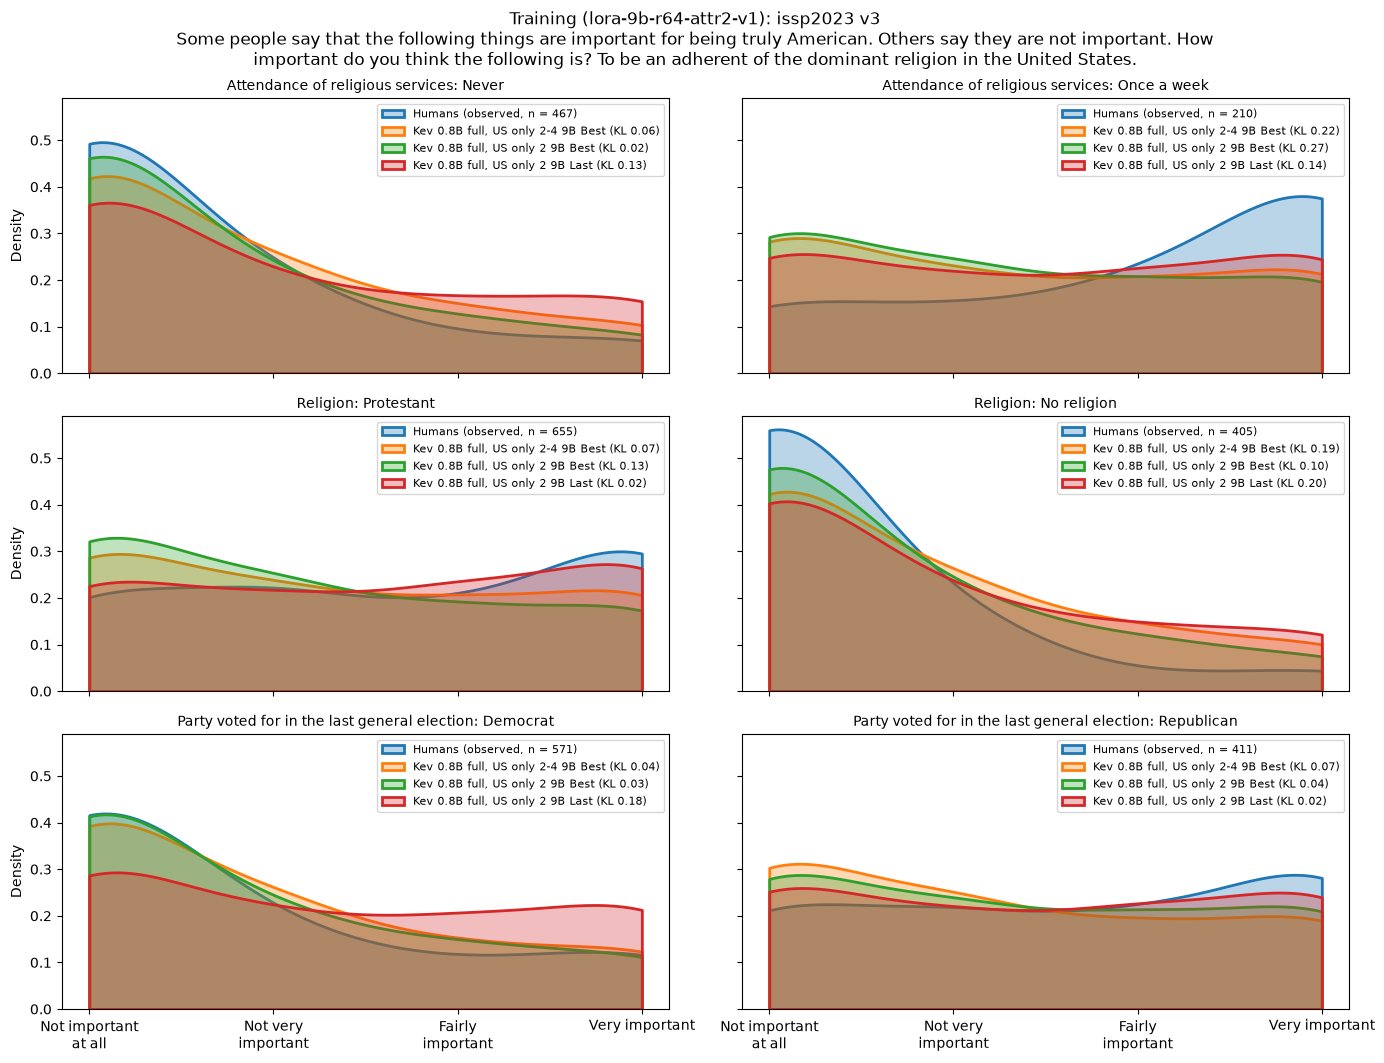

In [158]:
question, rows = issp_panels(RUN_DATA.slots)
plot_panels(f"Training ({TRAIN_RUN.name})", f"{TRAIN_RUN.name} training contrasts", question, rows)

### Calibration: a US question held out of training

runs/lora-9b-r64-v2/best: loaded from runs/predictions


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed


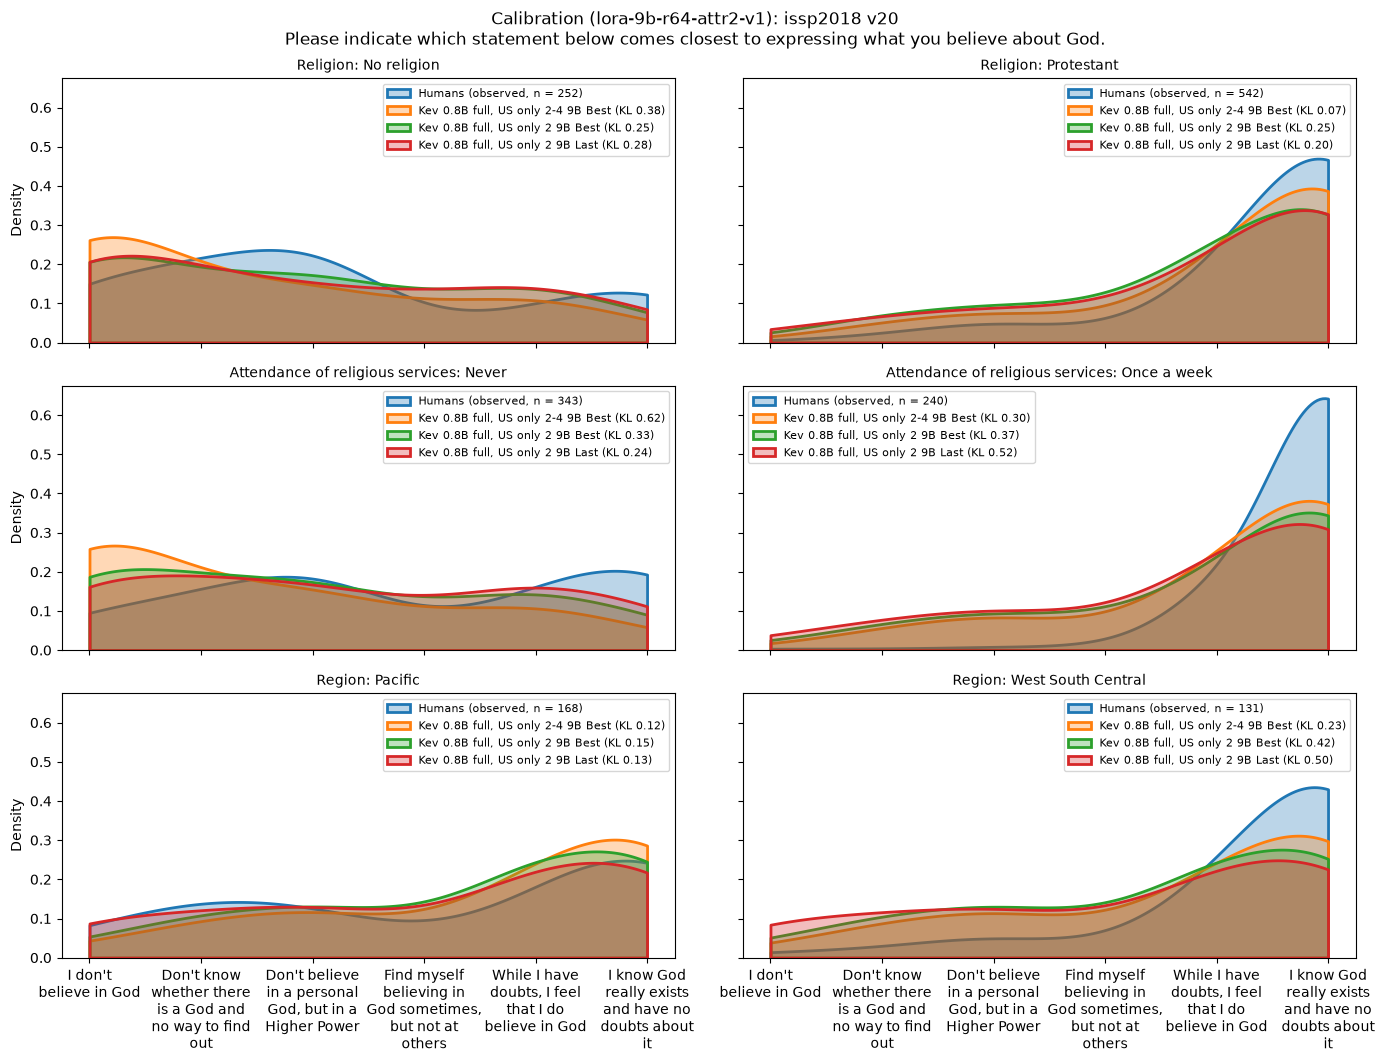

In [159]:
question, rows = issp_panels([s for s in SOURCE.held_out if SOURCE.units[s[0]].code == "US"])
plot_panels(f"Calibration ({TRAIN_RUN.name})", f"{TRAIN_RUN.name} calibration contrasts", question, rows)

### Test: a SubPOP question

### The same question in training (ISSP) and test (SubPOP)

Two questions asked in both surveys, in different words and on different answer scales: first the ISSP version(s) the run trained on, then the SubPOP version. Personas are chosen per question, as above.

#### A man's job is to earn money, a woman's to look after the home

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

runs/lora-9b-r64-attr2-v1/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed


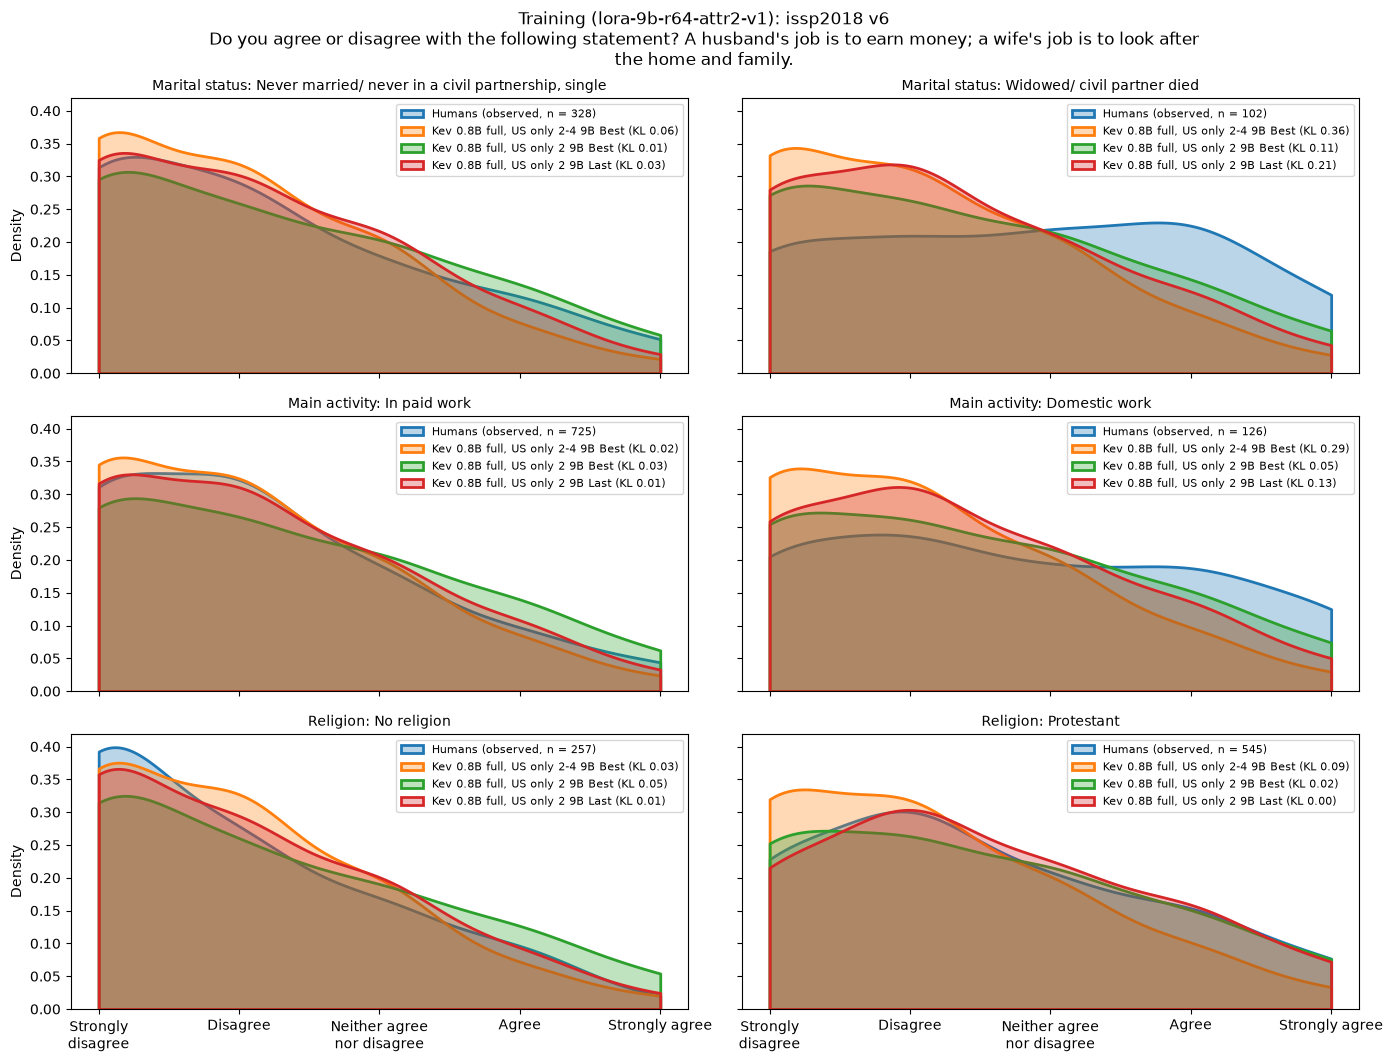

In [161]:
question, rows = issp_panels(RUN_DATA.slots, ("issp2018", "v6"))   # a husband's job is to earn money; a wife's job is to look after the home and family (5-point agree)
plot_panels(f"Training ({TRAIN_RUN.name})", f"{TRAIN_RUN.name} training issp2018 v6", question, rows)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

runs/lora-9b-r64-attr2-v1/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed


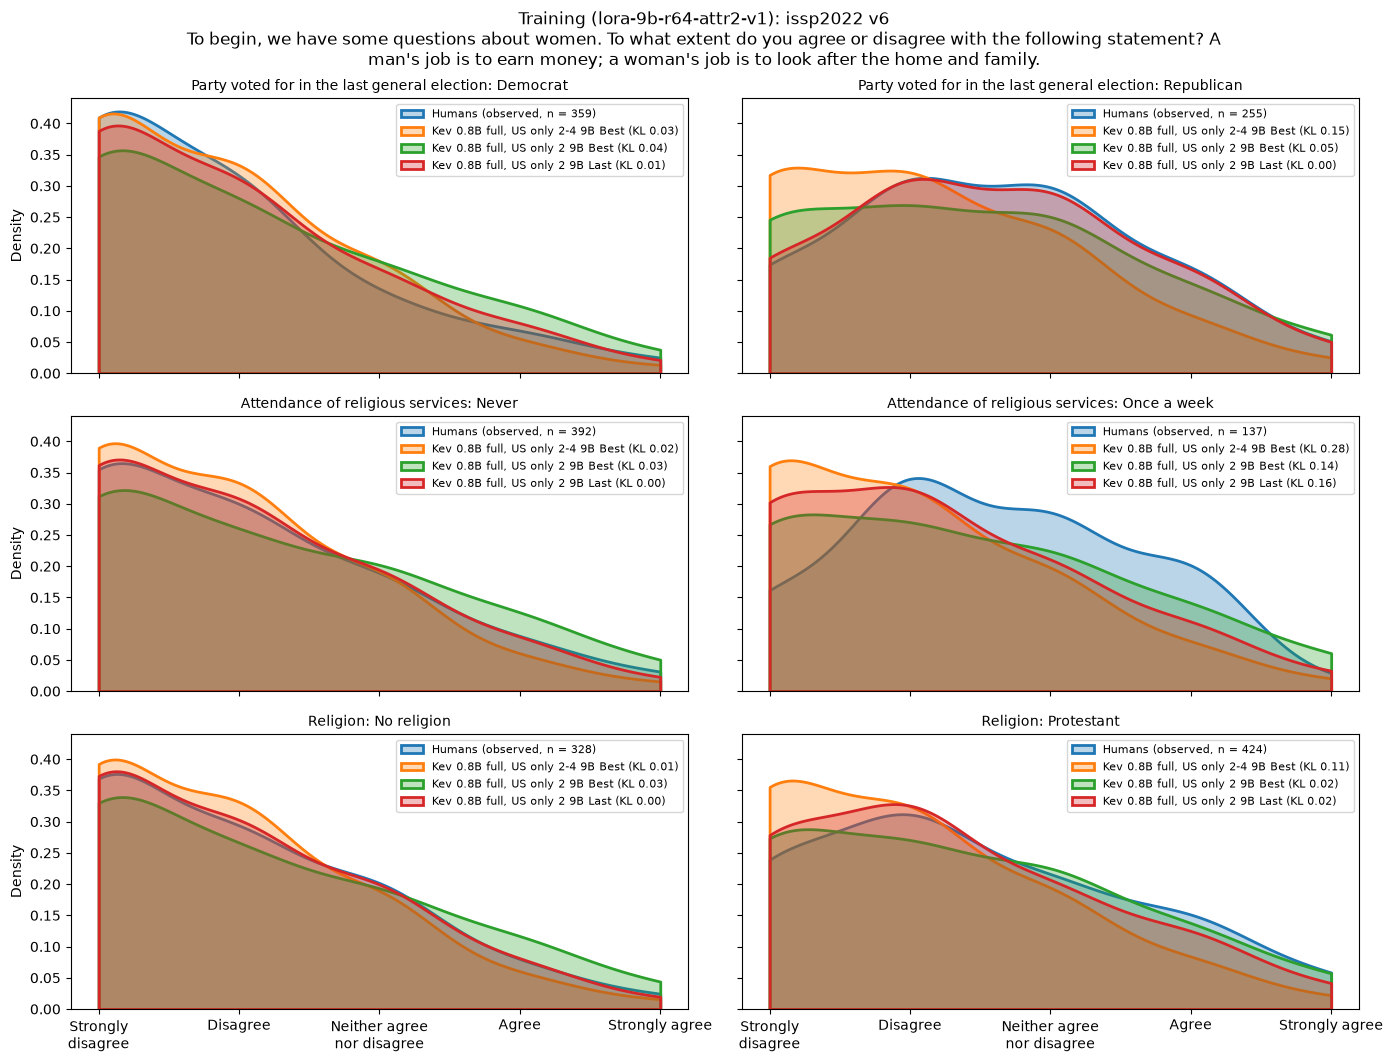

In [162]:
question, rows = issp_panels(RUN_DATA.slots, ("issp2022", "v6"))   # a man's job is to earn money; a woman's job is to look after the home and family (5-point agree)
plot_panels(f"Training ({TRAIN_RUN.name})", f"{TRAIN_RUN.name} training issp2022 v6", question, rows)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

runs/lora-9b-r64-attr2-v1/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed


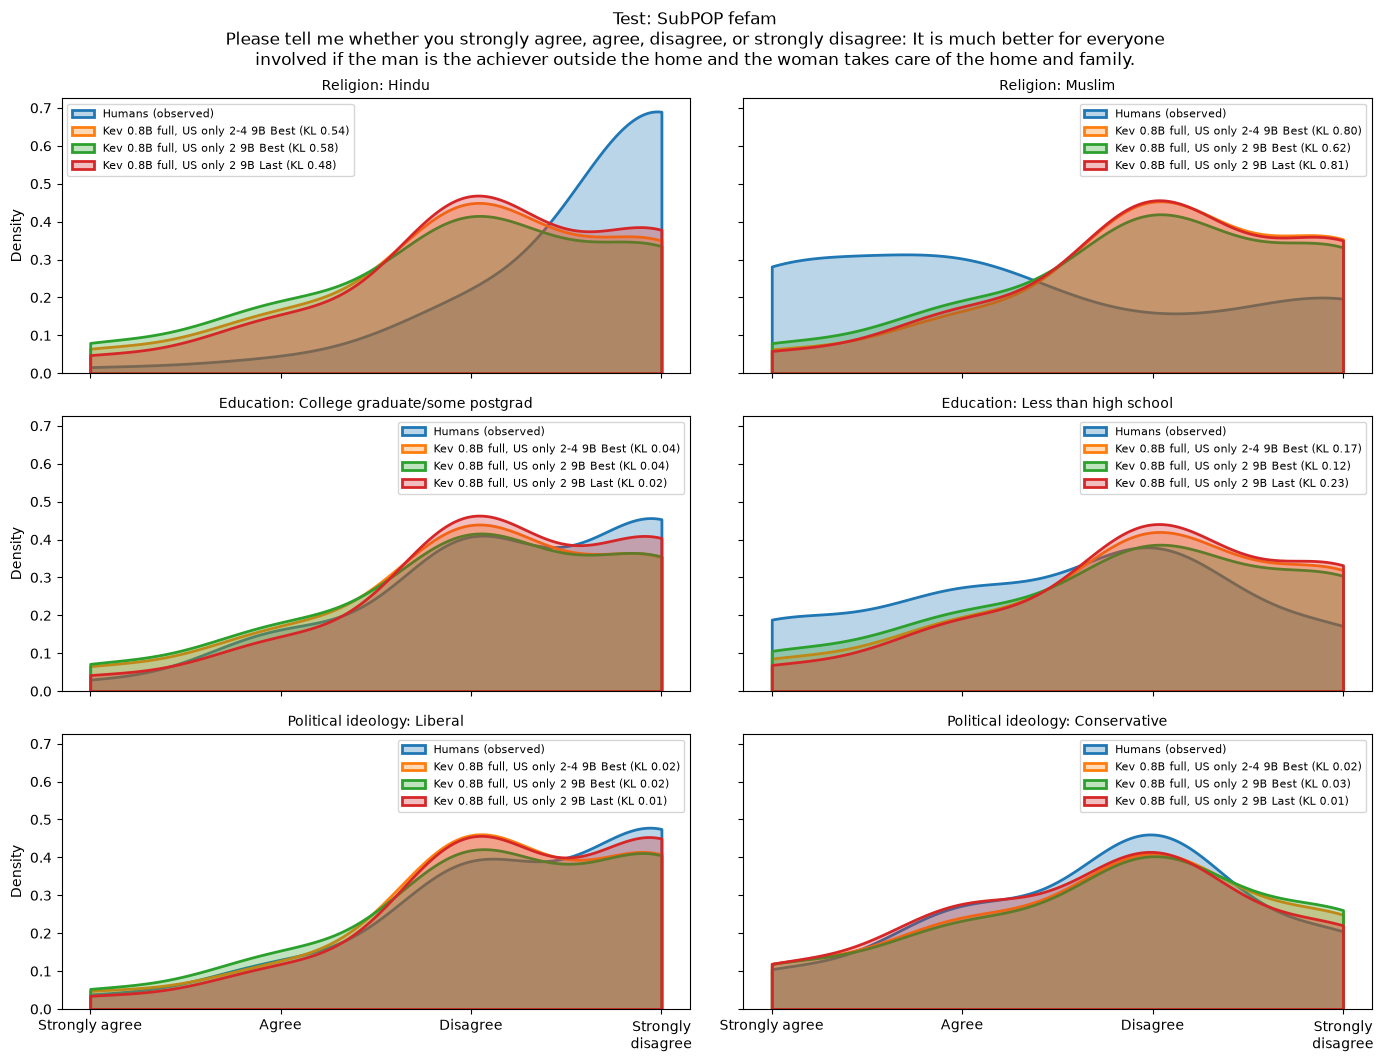

In [163]:
question, rows = test_panels("fefam")   # better if the man is the achiever outside the home and the woman takes care of the home and family (4-point agree)
plot_panels("Test", f"{TEST} fefam", question, rows)

#### How easy it would be to find a similar job

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

runs/lora-9b-r64-attr2-v1/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed


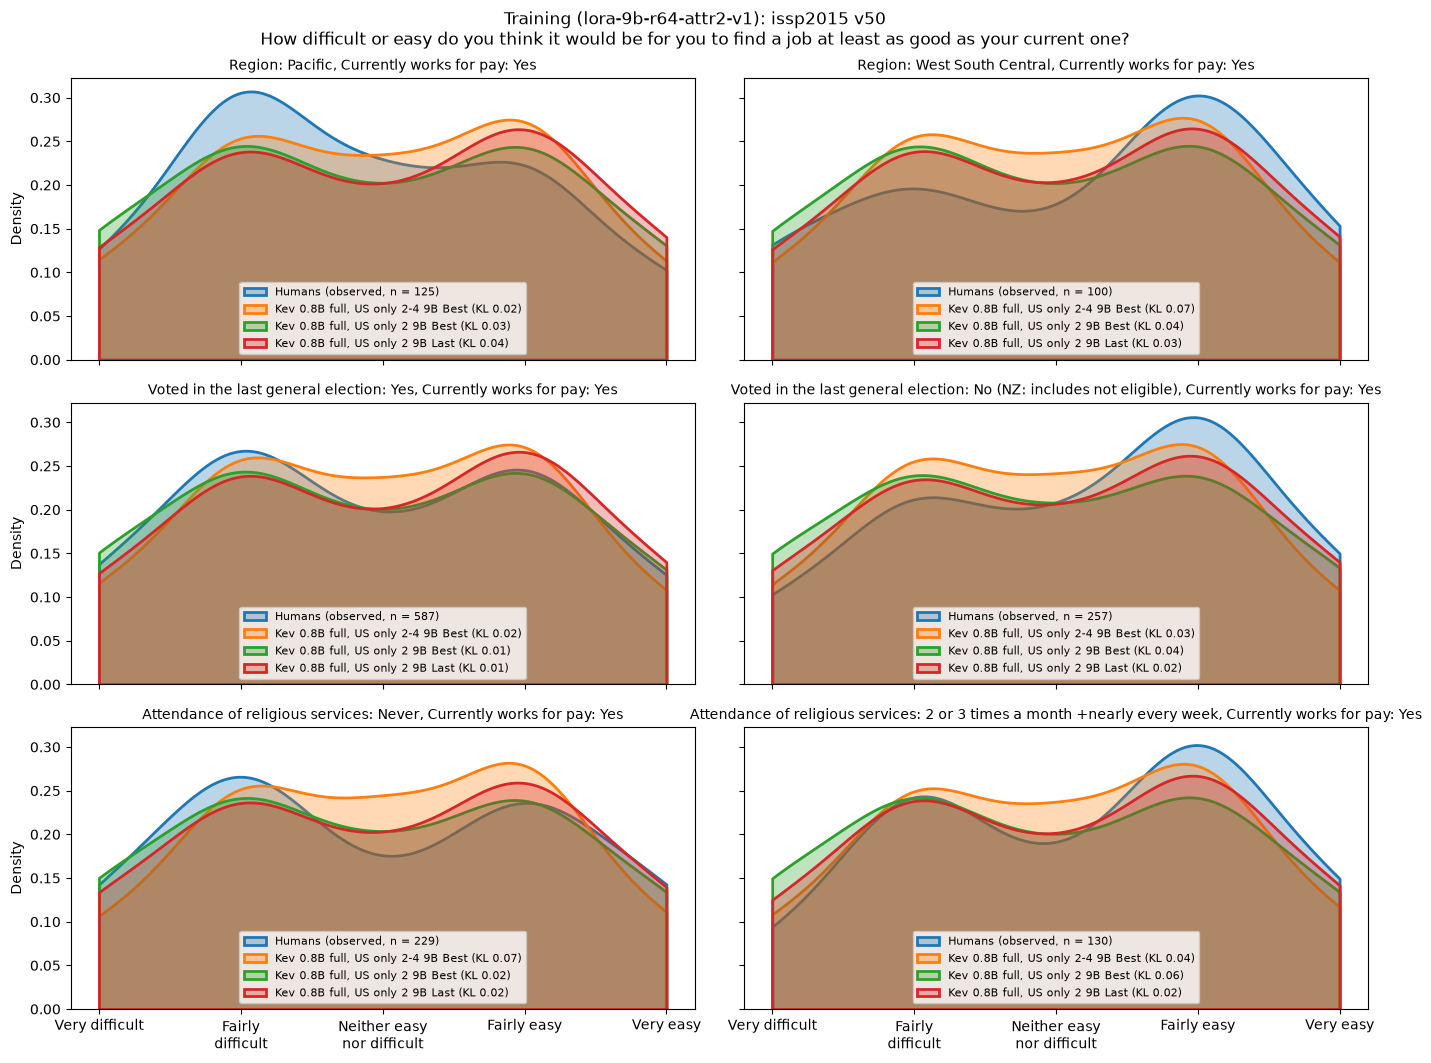

In [164]:
question, rows = issp_panels(RUN_DATA.slots, ("issp2015", "v50"))   # how difficult or easy it would be to find a job at least as good as the current one (5 points)
plot_panels(f"Training ({TRAIN_RUN.name})", f"{TRAIN_RUN.name} training issp2015 v50", question, rows)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

runs/lora-9b-r64-attr2-v1/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed


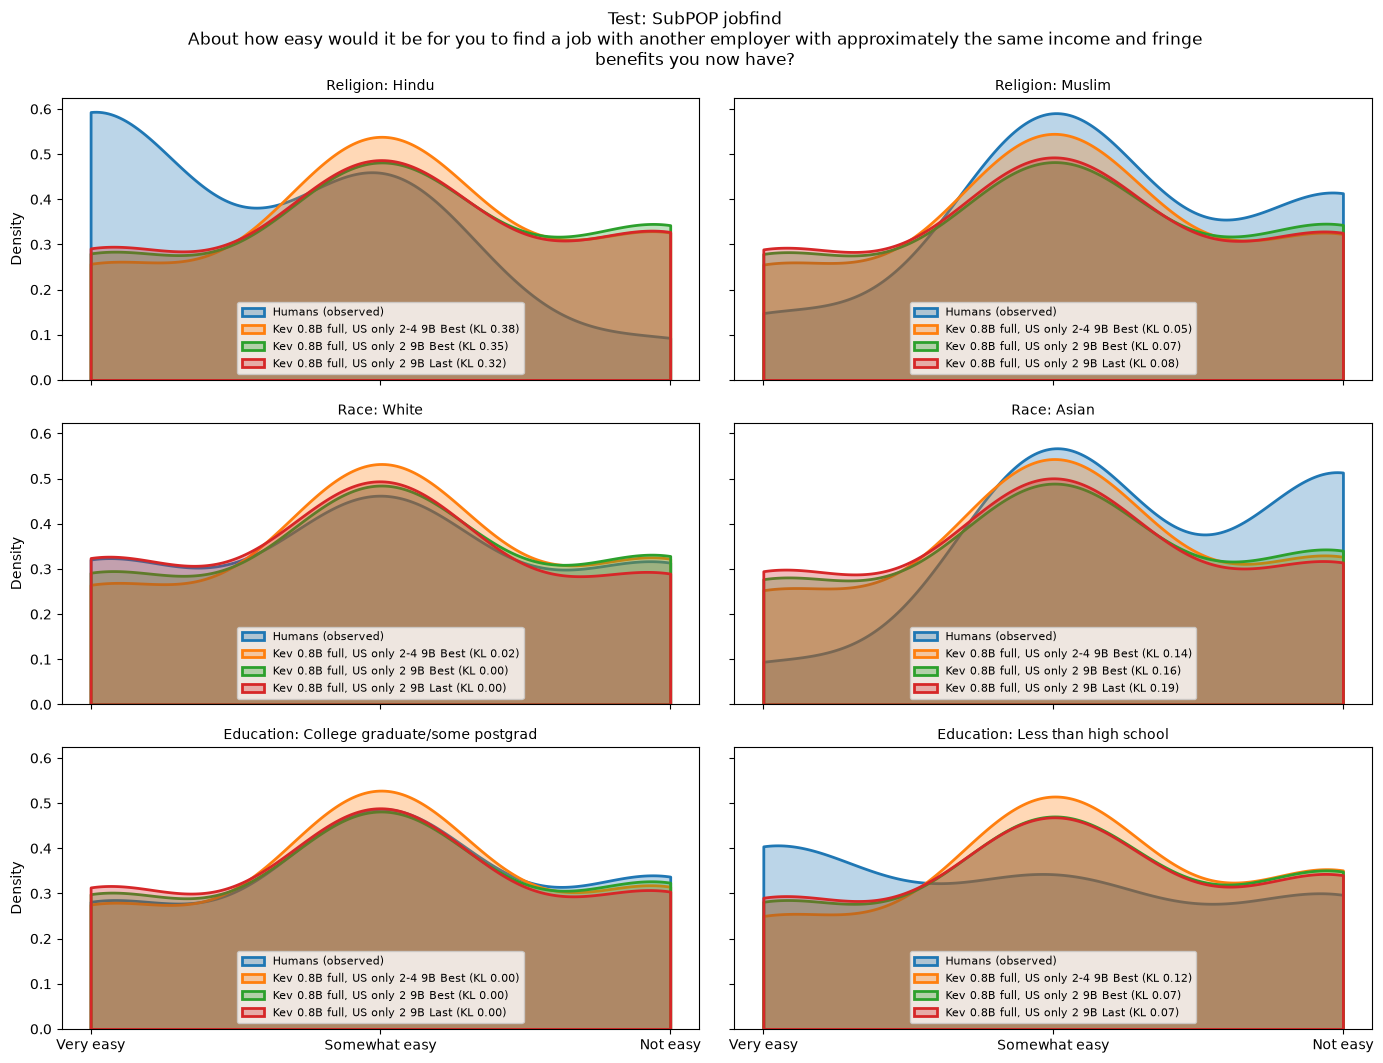

In [165]:
question, rows = test_panels("jobfind")   # how easy it would be to find a job with another employer with about the same income and benefits (3 points)
plot_panels("Test", f"{TEST} jobfind", question, rows)

## 3. Does the fine-tuned model use gender?

### On a training question

One ISSP training question on which women and men answer very differently: how household work is shared with the partner (ISSP 2022 v45; the largest average gap between women and men among all ISSP Likert questions). Three panels for the US (everyone living with a partner, as the question asks): men (observed vs fine-tuned), women (observed vs fine-tuned), and the fine-tuned prediction with no `Sex` line in the persona against men and women together. The records are aggregated from the respondent data from the respondent data (`IsspSource.group`). The question (US, v45) was a training slot, so the model trained on it, each epoch with a freshly drawn persona; whether it ever drew exactly these three personas is not recorded (section 2 shows records it certainly saw). So this shows what the model learned about the question, not how it generalises to new questions.

In [143]:
def plot_sex(dataset, v, country="US"):
    """Men, women and no Sex line for question v of one ISSP country: observed shares vs every model's prediction. With no
    Sex line, the observed shares are men and women together (each group's shares weighted by how many answered)."""
    source = IsspSource([dataset])
    records = {"Man": source.group(dataset, country, {"Sex": "Male"}, [v]),
               "Woman": source.group(dataset, country, {"Sex": "Female"}, [v]),
               "Sex not given": source.group(dataset, country, {}, [v])}
    set_name = f"{dataset} {v} sex"
    predicted = {name: cached_predictions(run, {set_name: list(records.values())})[set_name]   # one row per record, in order
                 for name, run in MODELS.items()}

    question = records["Man"]["questions"][v]
    n_men, n_women = records["Man"]["n"][v], records["Woman"]["n"][v]
    targets = predicted[next(iter(MODELS))]   # the observed shares: the same for every model
    both = (n_men * targets[0]["target"] + n_women * targets[1]["target"]) / (n_men + n_women)
    print("Persona:", ", ".join(f"{key}: {value}" for key, value in records["Sex not given"]["persona"].items()), "+ Sex")
    print("Question:", textwrap.fill(question["instructions"], 110))
    fig, axes = plt.subplots(1, len(records), figsize=(15, 4.5), sharex=True, sharey=True)
    for k, ((name, record), ax) in enumerate(zip(records.items(), axes)):
        observed, n = (both, n_men + n_women) if name == "Sex not given" else (targets[k]["target"], record["n"][v])
        curves = {HUMANS: observed} | {model: predicted[model][k]["probs"] for model in MODELS}
        legend = {HUMANS: f"Humans (observed, {'men and women, ' if name == 'Sex not given' else ''}n = {n})"}
        legend |= {model: f"{model} (KL {train.kl_divergence(observed, curves[model]):.2f})" for model in MODELS}
        plot_shares(ax, curves, question["criteria"], labels=legend)
        ax.set_title(name)
        ax.legend(fontsize=8)
    fig.suptitle(f"{dataset} {v}, {country}")
    plt.tight_layout()
    plt.show()


runs/lora-9b-r64-v2/best: loaded from runs/predictions
runs/lora-9b-r64-v2/last: loaded from runs/predictions
Persona: Country: United States, Lives with a spouse or partner: Yes + Sex
Question: Which of the following best applies to the sharing of household work between you and your spouse/partner?


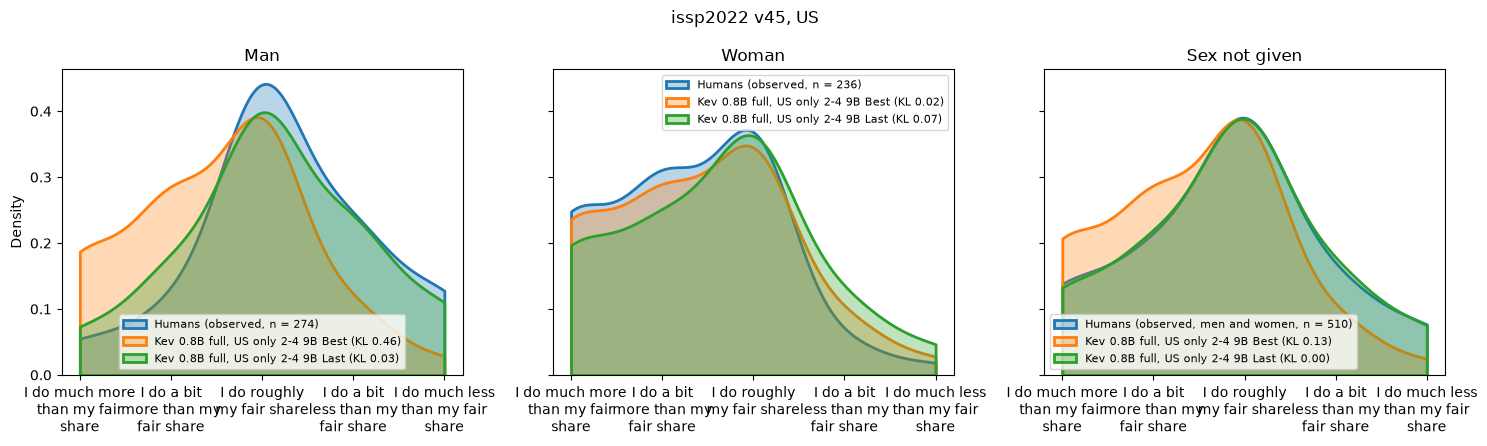

In [144]:
plot_sex("issp2022", "v45")   # sharing of household work with the spouse/partner; US


runs/lora-9b-r64-v2/best: loaded from runs/predictions
runs/lora-9b-r64-v2/last: loaded from runs/predictions
Persona: Country: United States + Sex
Question: Now thinking about the present... About how often do you pray?


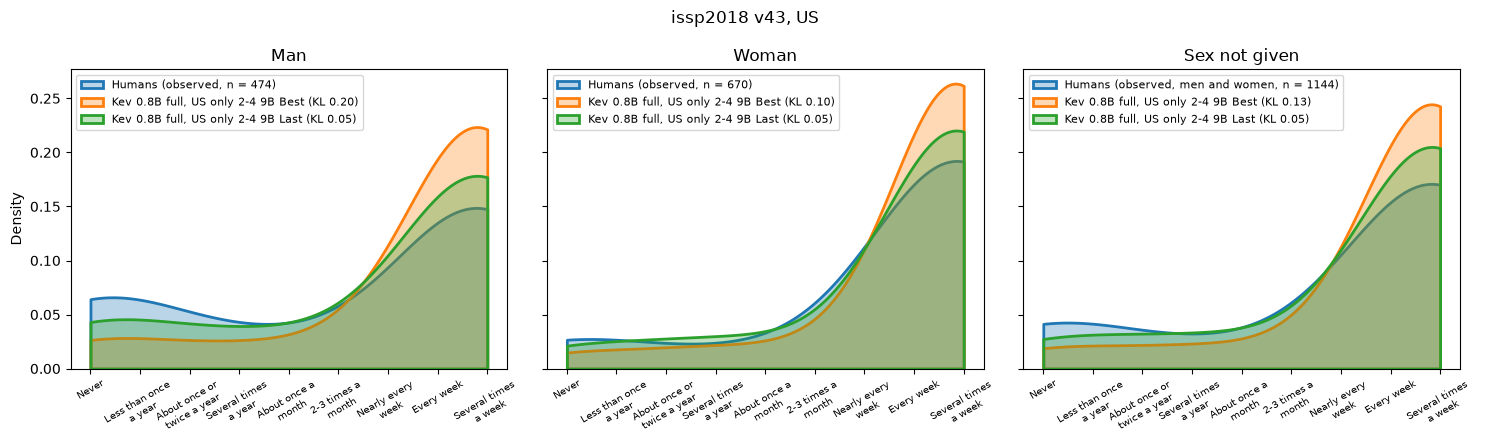

In [145]:
plot_sex("issp2018", "v43")   # how often they pray; US


runs/lora-9b-r64-v2/best: loaded from runs/predictions
runs/lora-9b-r64-v2/last: loaded from runs/predictions
Persona: Country: United States + Sex
Question: And do you think that nuclear power stations are …


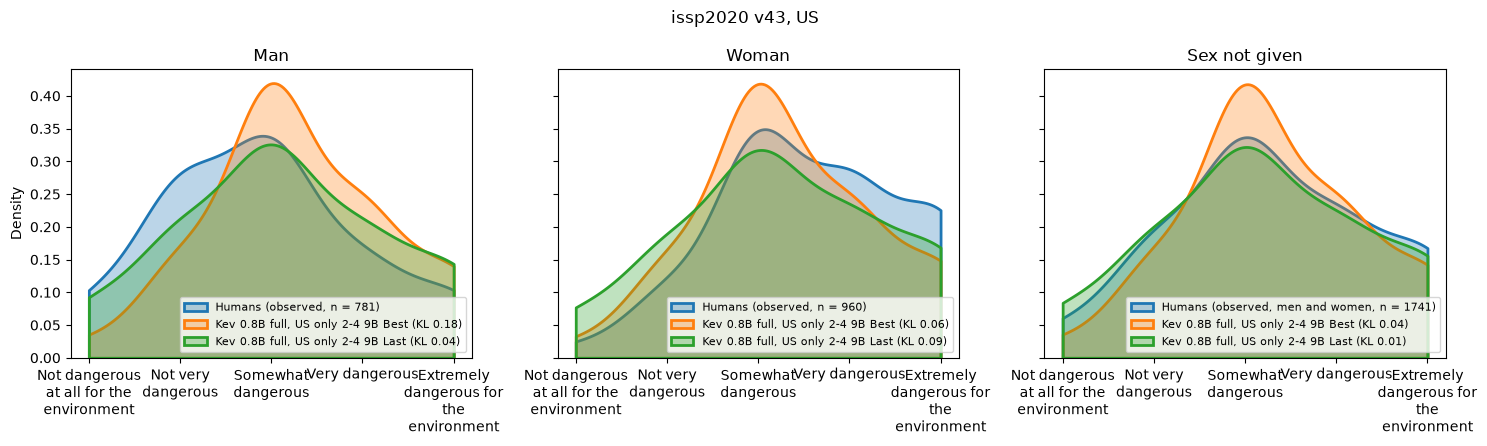

In [146]:
plot_sex("issp2020", "v43")   # nuclear power stations and the environment; US


runs/lora-9b-r64-v2/best: loaded from runs/predictions
runs/lora-9b-r64-v2/last: loaded from runs/predictions
Persona: Country: United States + Sex
Question: The next questions deal with robots and artificial intelligence. 'Artificial intelligence' is the ability of a
robot or computer to perform tasks commonly associated with humans. Various human actions can be done by
robots or Artificial Intelligence (AI). Using a scale from 0 to 10, how would you personally feel about the
following? '0' means that you would feel "totally uncomfortable" and '10' means that you would feel "totally
comfortable" with this situation. Being driven in a driverless car


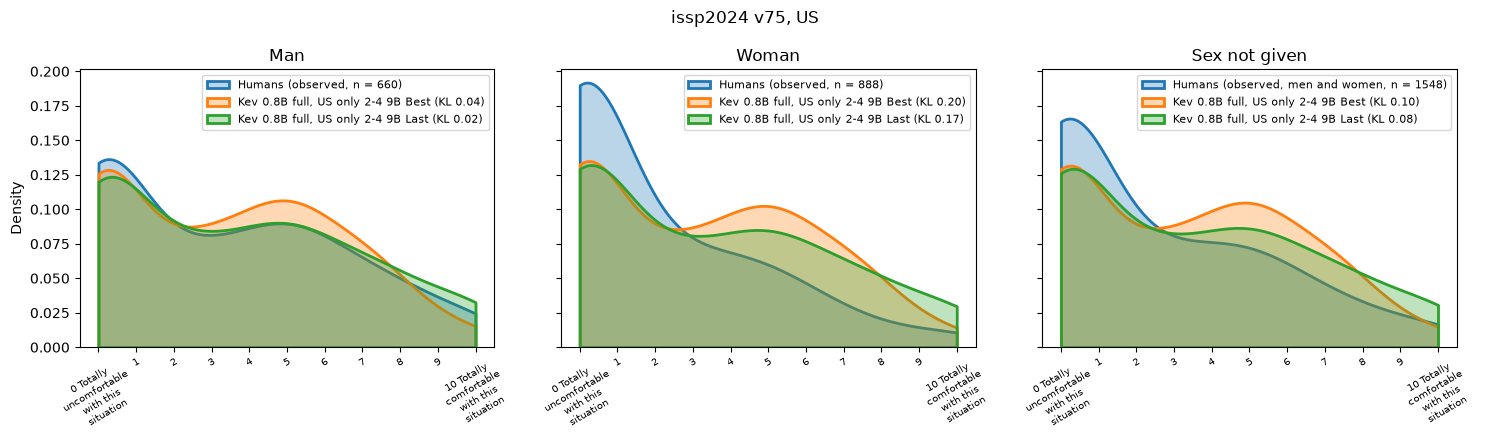

In [147]:
plot_sex("issp2024", "v75")   # comfortable being driven in a driverless car; US


runs/lora-9b-r64-v2/best: loaded from runs/predictions
runs/lora-9b-r64-v2/last: loaded from runs/predictions
Persona: Country: United States + Sex
Question: Do you believe in Religious miracles?


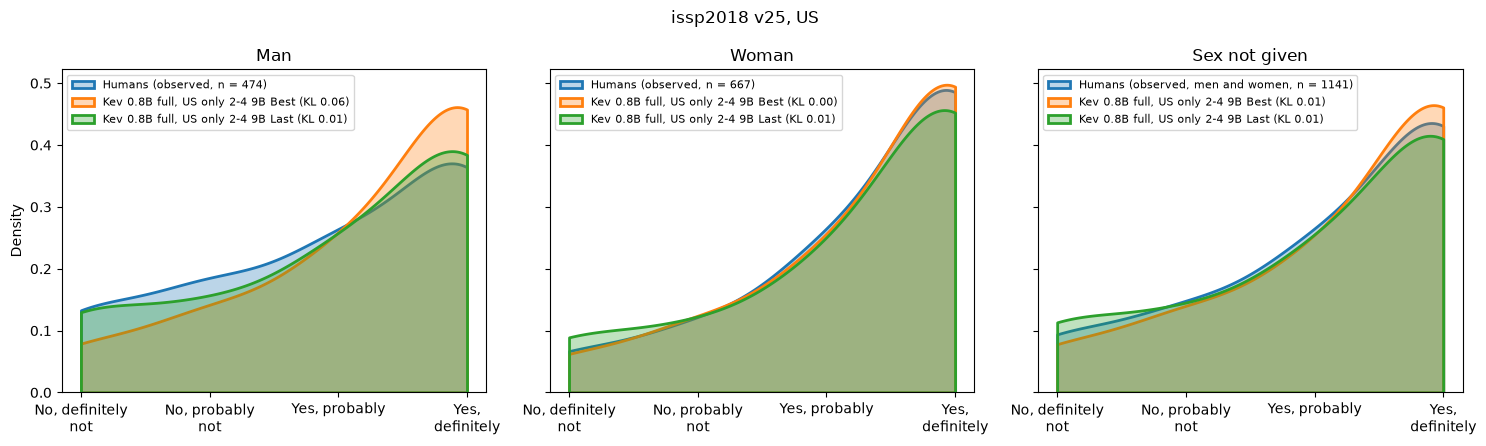

In [148]:
plot_sex("issp2018", "v25")   # belief in religious miracles; US


runs/lora-9b-r64-v2/best: loaded from runs/predictions
runs/lora-9b-r64-v2/last: loaded from runs/predictions
Persona: Country: United States + Sex
Question: Children grow up in different kinds of families. To what extent do you agree or disagree with the following
statement? A single mother can bring up her child as well as a married couple.


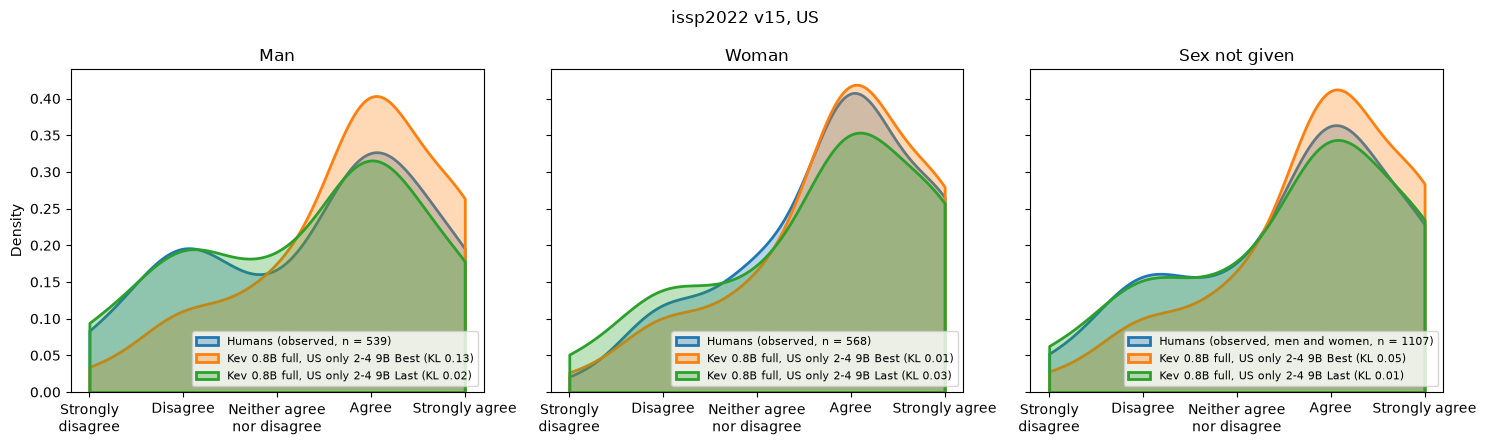

In [149]:
plot_sex("issp2022", "v15")   # a single mother can bring up a child as well as a married couple; US


### On a calibration question

A question the model was not trained on: one of the US calibration slots held out of training (1% of each year's US (question) slots, `calibration_frac` 0.01 in the run's recipe). Among the held-out US Likert questions, women and men differ most on ISSP 2018 v20: which statement comes closest to what they believe about God.

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/last: computed
Persona: Country: United States + Sex
Question: Please indicate which statement below comes closest to expressing what you believe about God.


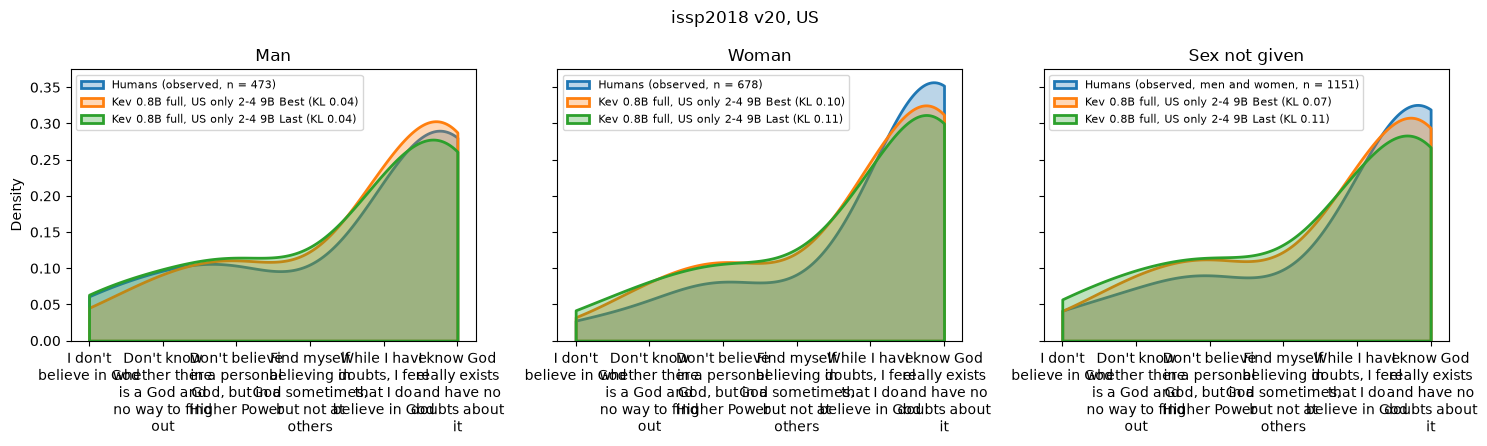

In [133]:
plot_sex("issp2018", "v20")   # belief in God; US (calibration slot)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/last: computed
Persona: Country: United States + Sex
Question: How much do you agree or disagree with the following statement? People should have access to publicly funded
health care even if they… do not hold citizenship of the United States.


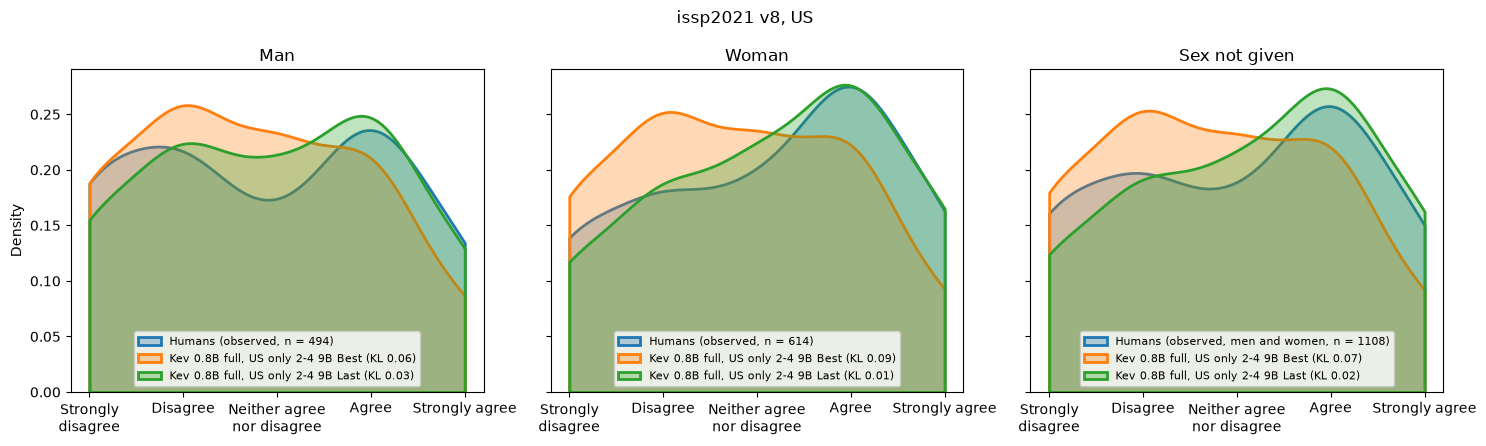

In [134]:
plot_sex("issp2021", "v8")   # publicly funded health care for people without US citizenship; US (calibration slot)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/best: computed


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-v2/last: computed
Persona: Country: United States + Sex
Question: Using the following scale ranging from 0 to 10, where 0 means "No trust at all" and 10 means "Complete trust",
please indicate how much trust you personally have in… ... The United States' courts


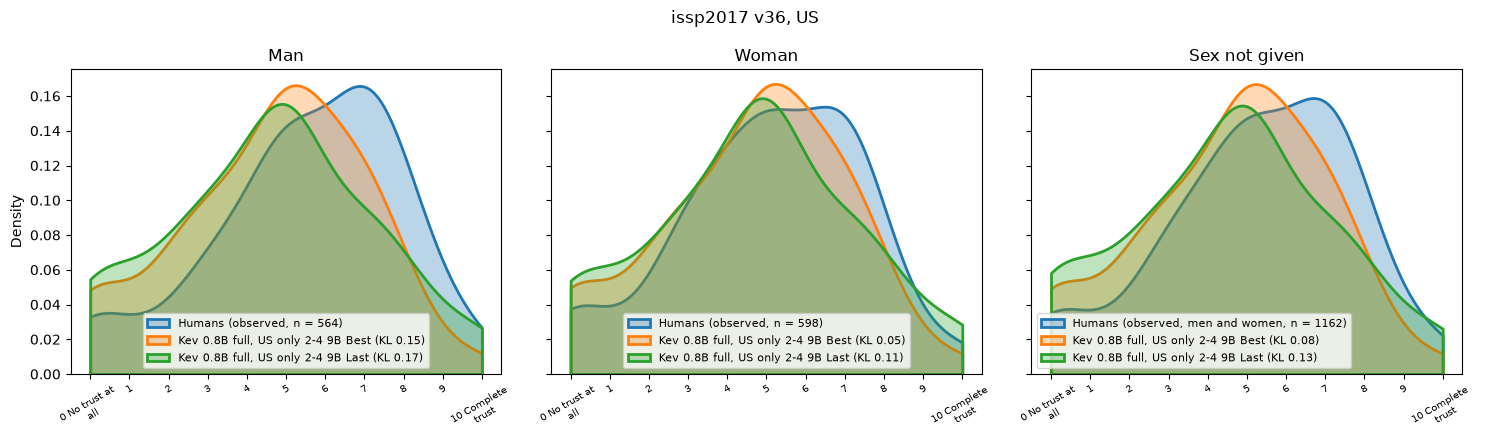

In [135]:
plot_sex("issp2017", "v36")   # trust in the US courts, 0-10; US (calibration slot)


## 4. The worst-predicted question rows

For one model in `MODELS` (`WORST_MODEL`) and one set (`WORST_SET`), the `WORST_TOP` question rows with the highest KL divergence: each with the exact text the model reads (its prompt, as `show_train_samples.py` prints it) and the observed vs predicted answer shares, in the order the options are shown.

- **training**: `TRAINING_DRAWS` records drawn as the run's training draws them (fixed seed, so the same draws each time), shown in the canonical view; training may have shown them differently (`--augment`).
- **calibration**: the run's calibration records. **test**: SubPOP's evaluation split.

Training and calibration need one of our runs (they are rebuilt from its `run_info.json`); a released model has only `test`.

In [170]:
import random

from IPython.display import display

WORST_MODEL = EX_MODEL     # a name in MODELS
WORST_SET = "calibration"  # "training", "calibration" or "test"
WORST_TOP = 10             # question rows shown
TRAINING_DRAWS = 500       # "training": records drawn as training draws them (seed 0), one per random training slot
device = 'cuda'

def run_data(run):
    """The training and calibration data of the run a checkpoint comes from, rebuilt from its recipe."""
    run_dir = Path(run).parent
    if run_dir == TRAIN_RUN:
        return RUN_DATA
    info = run_dir / "run_info.json"
    if not info.exists():
        raise ValueError(f"{run} is not one of our runs (a released model?): it has no training or calibration set; use 'test'")
    return TrainingData(recipe_from_settings(json.loads(info.read_text())["settings"]))

def set_records(run, which):
    """The records of one set: as stored (calibration, test), or drawn as training draws them (training)."""
    if which == "test":
        return test_records
    data = run_data(run)
    if which == "calibration":
        return data.calibration_records()
    rng = random.Random(0)
    return [data.draw(rng, slot) for slot in rng.sample(data.slots, min(TRAINING_DRAWS, len(data.slots)))]

def worst_rows(name, which, top):
    """The `top` question rows of a set with the highest KL divergence for one model: what the model read (its prompt)
    and the observed vs predicted answer shares."""
    run = MODELS[name]
    records = set_records(run, which)
    set_name = f"{Path(run).parent.name} {which}" + (f" draws{TRAINING_DRAWS}" if which == "training" else "")
    predicted = cached_predictions(run, {set_name: records}, device)[set_name]   # one row per question, in record order
    rows = [(record, v) for record in records for v in record["questions"]]
    kl = [float(train.kl_divergence(p["target"], p["probs"])) for p in predicted]
    encoder = models.load_encoder(run)
    print(f"{name} on {which}: {len(rows)} question rows, mean KL {np.mean(kl):.3f} bits; the {top} highest:")
    for rank, k in enumerate(np.argsort(kl)[::-1][:top], 1):
        record, v = rows[k]
        one = canonical({**record, "questions": {v: record["questions"][v]}})   # the row's question alone, as evaluated
        header, prompt = encoder.preview(one)
        (_, options), = [(q["instr"], q["options"]) for q in options_and_targets(one)[0]["questions"]]
        n = (record.get("n") or {}).get(v)
        print(f"\n{'=' * 110}\n#{rank}  KL {kl[k]:.3f} bits | {record['group']} | {v} ({record['questions'][v].get('src')}, "
              f"{record['questions'][v]['type']})" + (f" | n = {n}" if n else "") + f"\n{header}\n{'-' * 110}\n{prompt}\n{'-' * 110}")
        with pd.option_context("display.max_colwidth", None):   # whole option texts
            display(pd.DataFrame({"observed": predicted[k]["target"].numpy(), "predicted": predicted[k]["probs"].numpy()},
                                 index=options).round(3))

worst_rows(WORST_MODEL, WORST_SET, WORST_TOP)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

runs/lora-9b-r64-attr2-v1/last: computed
Kev 0.8B full, US only 2 9B Last on calibration: 2697 question rows, mean KL 0.161 bits; the 10 highest:

#1  KL 2.607 bits | US/Retired | v29 (issp2022, choice) | n = 142
107 tokens; state 11 of at most 384
--------------------------------------------------------------------------------------------------------------
<|fim_prefix|>
Country: United States
Main activity: Retired
<|fim_middle|>
Consider a family with a child under school age. What, in your opinion, is the best way for them to organise their family and work life? Which of these options would be the least desirable?
<|box_start|>Mother at home, father full-time<|box_end|>
<|box_start|>Mother part-time, father full-time<|box_end|>
<|box_start|>Both, mother and father full-time<|box_end|>
<|box_start|>Both, mother and father part-time<|box_end|>
<|box_start|>Father part-time, mother full-time<|box_end|>
<|box_start|>Father at home, mother full-time<|box_end|>
<|fim_suffix|>
-----------

,observed,predicted
"Mother at home, father full-time",0.049,0.256
"Mother part-time, father full-time",0.028,0.287
"Both, mother and father full-time",0.366,0.336
"Both, mother and father part-time",0.106,0.113
"Father part-time, mother full-time",0.063,0.004
"Father at home, mother full-time",0.387,0.004


...

,observed,predicted
"Mother at home, father full-time",0.070,0.240
"Mother part-time, father full-time",0.031,0.281
"Both, mother and father full-time",0.398,0.355
"Both, mother and father part-time",0.086,0.115
"Father part-time, mother full-time",0.055,0.004
"Father at home, mother full-time",0.359,0.005



#9  KL 2.259 bits | US/Married | v29 (issp2022, choice) | n = 303
107 tokens; state 11 of at most 384
--------------------------------------------------------------------------------------------------------------
<|fim_prefix|>
Country: United States
Marital status: Married
<|fim_middle|>
Consider a family with a child under school age. What, in your opinion, is the best way for them to organise their family and work life? Which of these options would be the least desirable?
<|box_start|>Mother at home, father full-time<|box_end|>
<|box_start|>Mother part-time, father full-time<|box_end|>
<|box_start|>Both, mother and father full-time<|box_end|>
<|box_start|>Both, mother and father part-time<|box_end|>
<|box_start|>Father part-time, mother full-time<|box_end|>
<|box_start|>Father at home, mother full-time<|box_end|>
<|fim_suffix|>
--------------------------------------------------------------------------------------------------------------


,observed,predicted
"Mother at home, father full-time",0.079,0.258
"Mother part-time, father full-time",0.013,0.270
"Both, mother and father full-time",0.409,0.361
"Both, mother and father part-time",0.132,0.105
"Father part-time, mother full-time",0.026,0.003
"Father at home, mother full-time",0.340,0.003



#10  KL 2.240 bits | US/England and Wales | v29 (issp2022, choice) | n = 164
109 tokens; state 13 of at most 384
--------------------------------------------------------------------------------------------------------------
<|fim_prefix|>
Country: United States
Ancestry: England and Wales
<|fim_middle|>
Consider a family with a child under school age. What, in your opinion, is the best way for them to organise their family and work life? Which of these options would be the least desirable?
<|box_start|>Mother at home, father full-time<|box_end|>
<|box_start|>Mother part-time, father full-time<|box_end|>
<|box_start|>Both, mother and father full-time<|box_end|>
<|box_start|>Both, mother and father part-time<|box_end|>
<|box_start|>Father part-time, mother full-time<|box_end|>
<|box_start|>Father at home, mother full-time<|box_end|>
<|fim_suffix|>
--------------------------------------------------------------------------------------------------------------


,observed,predicted
"Mother at home, father full-time",0.067,0.254
"Mother part-time, father full-time",0.006,0.274
"Both, mother and father full-time",0.482,0.347
"Both, mother and father part-time",0.110,0.119
"Father part-time, mother full-time",0.012,0.002
"Father at home, mother full-time",0.323,0.003
